<a href="https://colab.research.google.com/github/NethsanduKumarasinghe/CNN_ImageClassification/blob/main/Fitting_and_Alignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

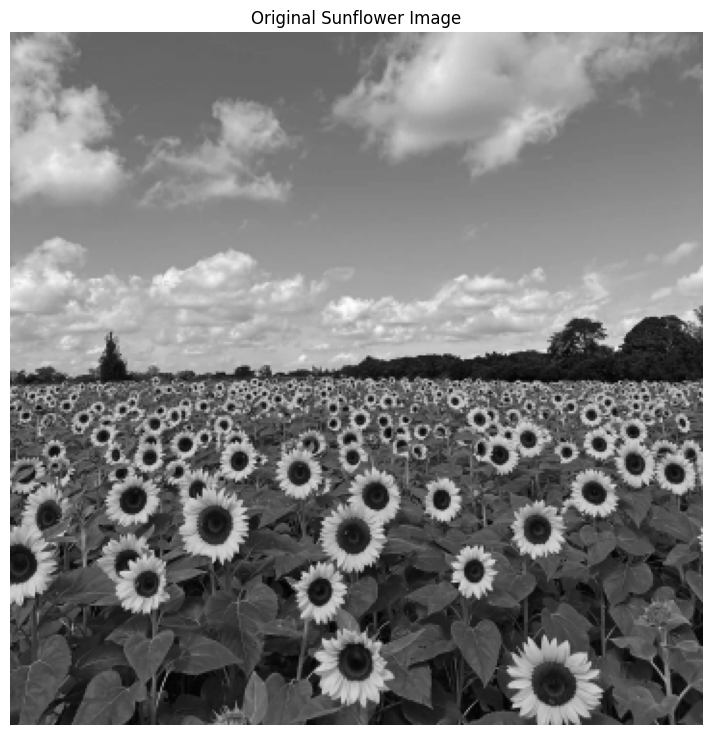

Image dimensions: (360, 360)


In [17]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

# Read the sunflower image at a reduced resolution
image = cv.imread(
    '/the_berry_farms_sunflower_field.jpeg',
    cv.IMREAD_REDUCED_COLOR_4
)

assert image is not None, "Could not load the sunflower image."

# Convert the image to grayscale and normalize pixel values
gray_image = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0

# Display the input image
plt.figure(figsize=(9, 9))
plt.imshow(gray_image, cmap='gray')
plt.title('Original Sunflower Image')
plt.axis('off')
plt.show()

print("Image dimensions:", gray_image.shape)

In [29]:
# Define the scales to examine
scales = np.linspace(1, 8, 10)

# Set the threshold for accepting blob responses
response_threshold = 0.6

# Store the detected blobs
detected_blobs = []

height, width = gray_image.shape

for sigma in scales:

    print(f"Processing sigma = {sigma:.2f}")

    # Construct the LoG kernel
    half_size = round(3 * sigma)
    xx, yy = np.meshgrid(
        np.arange(-half_size, half_size + 1),
        np.arange(-half_size, half_size + 1)
    )

    distance_squared = xx**2 + yy**2

    log_kernel = (
        (distance_squared / (2 * sigma**2) - 1)
        * np.exp(-distance_squared / (2 * sigma**2))
        / (np.pi * sigma**4)
    )

    # Normalize the filter response with sigma squared
    log_kernel = sigma**2 * log_kernel

    # Apply the filter and calculate the squared response
    response = cv.filter2D(
        gray_image, cv.CV_32F, log_kernel
    )
    response = response**2

    # Find local maxima in a 3 x 3 neighbourhood
    neighbourhood_max = maximum_filter(response, size=3)

    # Keep local maxima whose responses exceed the threshold
    threshold_value = response_threshold * response.max()

    maxima_mask = (
        (response == neighbourhood_max)
        & (response >= threshold_value)
    )

    # Get the coordinates of the detected maxima
    rows, cols = np.where(maxima_mask)

    for row, col in zip(rows, cols):
        detected_blobs.append(
            (col, row, sigma, response[row, col])
        )

print("\nTotal candidate detections:", len(detected_blobs))

Processing sigma = 1.00
Processing sigma = 1.78
Processing sigma = 2.56
Processing sigma = 3.33
Processing sigma = 4.11
Processing sigma = 4.89
Processing sigma = 5.67
Processing sigma = 6.44
Processing sigma = 7.22
Processing sigma = 8.00

Total candidate detections: 131


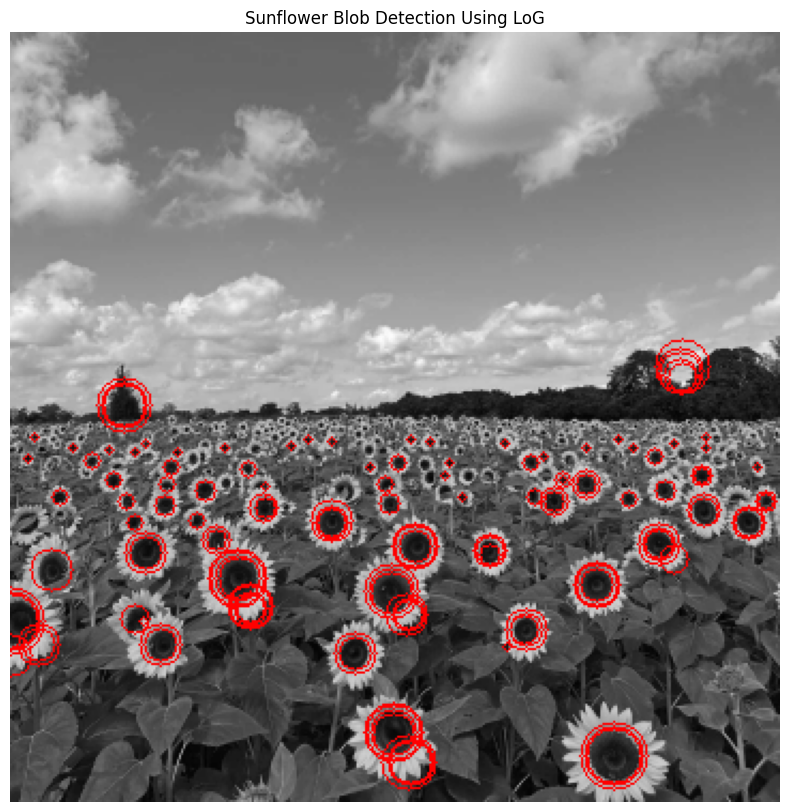

Ten strongest detections:
No. | Centre (x, y) | Sigma | Estimated radius | Response
 1  | ( 306,  214) | 2.56  |   5 | 0.15395
 2  | ( 323,  207) | 2.56  |   5 | 0.14183
 3  | ( 224,  242) | 3.33  |   7 | 0.13891
 4  | ( 269,  211) | 2.56  |   5 | 0.13780
 5  | ( 118,  222) | 3.33  |   7 | 0.13550
 6  | ( 345,  229) | 3.33  |   7 | 0.13541
 7  | ( 303,  239) | 4.11  |   8 | 0.13408
 8  | (  72,  221) | 2.56  |   5 | 0.13299
 9  | ( 181,  201) | 1.78  |   4 | 0.12954
10  | ( 289,  218) | 1.78  |   4 | 0.12718

Strongest detection:
Centre: (306, 214)
Sigma: 2.56
Estimated radius: 5 pixels
Response strength: 0.15395


In [30]:
# Sort the detections by response strength
detected_blobs.sort(key=lambda item: item[3], reverse=True)

# Prepare the image for drawing
result_image = cv.cvtColor(
    (gray_image * 255).astype(np.uint8),
    cv.COLOR_GRAY2BGR
)

# Draw circles around the detected blobs
for x, y, sigma, strength in detected_blobs:

    radius = max(1, int(round(2 * sigma)))

    cv.circle(
        result_image,
        (int(x), int(y)),
        radius,
        (0, 0, 255),
        1
    )

# Display the detection result
plt.figure(figsize=(10, 10))
plt.imshow(cv.cvtColor(result_image, cv.COLOR_BGR2RGB))
plt.title('Sunflower Blob Detection Using LoG')
plt.axis('off')
plt.show()

# Report the largest detections by response strength
print("Ten strongest detections:")
print("No. | Centre (x, y) | Sigma | Estimated radius | Response")

for index, (x, y, sigma, strength) in enumerate(
    detected_blobs[:10], start=1
):
    radius = max(1, int(round(2 * sigma)))

    print(
        f"{index:2d}  | ({x:4d}, {y:4d})"
        f" | {sigma:.2f}  | {radius:3d}"
        f" | {strength:.5f}"
    )

if detected_blobs:
    largest = max(detected_blobs, key=lambda item: item[3])
    x, y, sigma, strength = largest

    print("\nStrongest detection:")
    print(f"Centre: ({x}, {y})")
    print(f"Sigma: {sigma:.2f}")
    print(f"Estimated radius: {round(2 * sigma)} pixels")
    print(f"Response strength: {strength:.5f}")